# Learn locally, recurse globally: demo

This notebook shows the trained truth-table-to-circuit model and the outer loop of the paper
*Learn Locally, Recurse Globally: Neural Circuit Synthesis Beyond Training Depth*.

1. load a few test circuits and see how circuits are tokenized and drawn;
2. see how a truth table is fed to the model and how the model emits a circuit;
3. **one-shot** inference: exact on shallow circuits (the depth the model was trained on);
4. on deeper circuits the one-shot answer has errors, and **XOR residual refinement**
   corrects them by calling the same model on the residual.

The model was trained only on circuits of depth at most 2.

In [1]:
import sys, json
sys.path.insert(0, '..')   # run from notebooks/: make the llrg package importable
import numpy as np
from IPython.display import display

from llrg import CircuitSynthesizer, circuit as C, harness as H
from llrg.vocab import TOKENS, DISPLAY, tokenize
from llrg.viz import show_tables

model = CircuitSynthesizer.from_pretrained('../weights')   # CPU by default
print(f'{sum(p.numel() for p in model.parameters()):,} parameters')

samples = json.load(open('../samples/samples.json'))['samples']
for s in samples:
    print(f"{s['id']:24s} n={s['n']} m={s['m']}  gates={s['circuit_stats']['gates']:2d}  depth={s['circuit_stats']['depth']}")

2,203,136 parameters
shallow_n4_m4_q2_0       n=4 m=4  gates=11  depth=2
shallow_n4_m4_q2_1       n=4 m=4  gates=19  depth=2
shallow_n4_m4_q2_2       n=4 m=4  gates=11  depth=2
shallow_n3_m3_q2_0       n=3 m=3  gates=10  depth=3
deep_n4_m4_q6_0          n=4 m=4  gates=21  depth=5
deep_n4_m4_q6_b0         n=4 m=4  gates=27  depth=4
deep_n4_m4_q6_b1         n=4 m=4  gates=41  depth=5


## 1. Circuits as token sequences

A circuit with `m` outputs is written as one infix expression per output, separated by a
newline token. Variables are the digits `0`..`4` (inputs `x0`..`x4`), gates are `∧` (AND),
`∨` (OR), `⊻` (XOR) and the prefix `~` (NOT). The vocabulary has 16 tokens.

In [2]:
sample = samples[0]
print(sample['circuit'])
print()
ids = tokenize(sample['circuit'])
print('token ids:', ids)
print('tokens   :', [DISPLAY[TOKENS[i]] for i in ids])

( 1 ⊻ 2 ) ⊻ ~ 2
~ ( 0 ∧ 2 ∧ 3 )
( 0 ∧ 3 ) ⊻ ( 0 ∨ 1 )
1 ∨ 2 ∨ 3

token ids: [0, 8, 12, 4, 13, 9, 4, 5, 13, 10, 5, 8, 11, 2, 13, 2, 14, 9, 10, 8, 11, 2, 14, 9, 4, 8, 11, 3, 12, 9, 10, 12, 3, 13, 3, 14, 1]
tokens   : ['<start>', '(', 'x1', 'XOR', 'x2', ')', 'XOR', 'NOT', 'x2', '<next output>', 'NOT', '(', 'x0', 'AND', 'x2', 'AND', 'x3', ')', '<next output>', '(', 'x0', 'AND', 'x3', ')', 'XOR', '(', 'x0', 'OR', 'x1', ')', '<next output>', 'x1', 'OR', 'x2', 'OR', 'x3', '<end>']


The token sequence is parsed into one expression tree per output, which can be evaluated
on all `2^n` inputs and drawn with standard gate symbols.

y0 = (x1 XOR x2) XOR NOT x2
y1 = NOT (x0 AND x2 AND x3)
y2 = (x0 AND x3) XOR (x0 OR x1)
y3 = x1 OR x2 OR x3
{'outputs': 4, 'gates': 11, 'depth': 2}


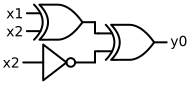

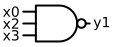

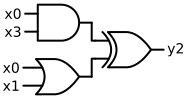

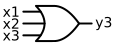

In [3]:
target = C.parse(sample['circuit'])
for j, o in enumerate(target):
    print(f'y{j} = {C.pretty(o)}')
print(C.stats(target))
for d in C.draw(target):
    display(d)

## 2. The truth table is the model's input

The model only sees the output columns `Y` of the truth table (the inputs are implicit in
the row order, `x0` most significant). Each cell is embedded as a bit plus a **strided**
position `r * 5 + j` (row `r`, column `j`), so the same cell keeps the same index whatever
the number of inputs and outputs of the table.

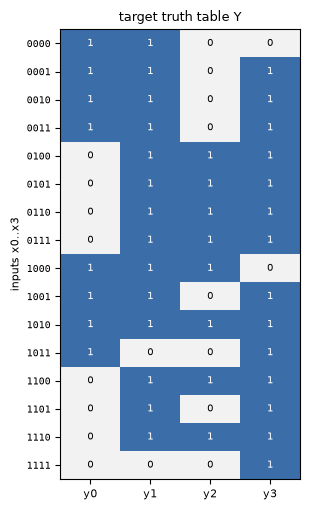

encoder positions (first 3 rows):
tensor([[ 0,  1,  2,  3],
        [ 5,  6,  7,  8],
        [10, 11, 12, 13]])


In [4]:
n, m = sample['n'], sample['m']
Y = np.array(sample['truth_table'], dtype=np.uint8)
assert (C.evaluate(target, n) == Y).all()   # the circuit computes this table
show_tables([Y], ['target truth table Y'], n)
print('encoder positions (first 3 rows):')
print(model.encoder.positions(2 ** n, m).view(2 ** n, m)[:3])

## 3. One-shot inference on a shallow circuit

One forward pass: the decoder emits a circuit token by token (greedy decoding). The circuit is
parsed, evaluated, and compared with the target table.

We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.
You may ignore this warning if your `pad_token_id` (0) is identical to the `bos_token_id` (0), `eos_token_id` (1), or the `sep_token_id` (None), and your input is not padded.


generated: <start> ( x1 XOR x3 ) XOR NOT x3 <next output> NOT ( x0 AND x2 AND x3 ) <next output> ( x0 AND x3 ) XOR ( x0 OR x1 ) <next output> x1 OR x2 OR x3 <end>
y0 = (x1 XOR x3) XOR NOT x3
y1 = NOT (x0 AND x2 AND x3)
y2 = (x0 AND x3) XOR (x0 OR x1)
y3 = x1 OR x2 OR x3
wrong cells: 0 of 64  (0.0%)   model circuit: {'outputs': 4, 'gates': 11, 'depth': 2}   target circuit: {'outputs': 4, 'gates': 11, 'depth': 2}


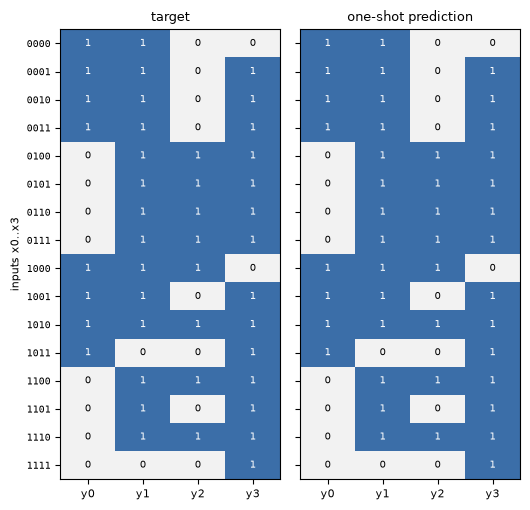

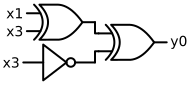

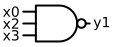

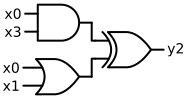

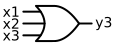

In [5]:
def run_one_shot(sample):
    n = sample['n']
    Y = np.array(sample['truth_table'], dtype=np.uint8)
    outs, pred, ids = H.one_shot(model, Y)
    print('generated:', ' '.join(DISPLAY[TOKENS[i]] for i in ids))
    if outs is None:
        print('the generated sequence is not a valid circuit')
        return None, None
    for j, o in enumerate(outs):
        print(f'y{j} = {C.pretty(o)}')
    wrong = pred != Y
    print(f'wrong cells: {int(wrong.sum())} of {Y.size}  ({wrong.mean():.1%})   model circuit: {C.stats(outs)}'
          f'   target circuit: {sample["circuit_stats"]}')
    show_tables([Y, pred], ['target', 'one-shot prediction'], n, wrong=[None, wrong])
    return outs, pred

outs, pred = run_one_shot(samples[0])
for d in C.draw(outs):
    display(d)

The model's circuit is not necessarily the same as the target circuit, but it computes the
same function. The other shallow samples:

==== shallow_n4_m4_q2_1


generated: <start> x0 AND x2 AND x3 AND NOT x1 <next output> ( x0 AND x1 AND x2 AND x3 ) XOR ( x1 AND x2 ) <next output> ( x0 AND x2 AND x3 ) OR ( x1 AND x2 AND x3 ) OR ( x2 XOR x3 ) <next output> ( x0 OR x1 OR x2 OR x3 ) XOR NOT x0 <end>
y0 = x0 AND x2 AND x3 AND NOT x1
y1 = (x0 AND x1 AND x2 AND x3) XOR (x1 AND x2)
y2 = (x0 AND x2 AND x3) OR (x1 AND x2 AND x3) OR (x2 XOR x3)
y3 = (x0 OR x1 OR x2 OR x3) XOR NOT x0
wrong cells: 0 of 64  (0.0%)   model circuit: {'outputs': 4, 'gates': 21, 'depth': 2}   target circuit: {'outputs': 4, 'gates': 19, 'depth': 2}


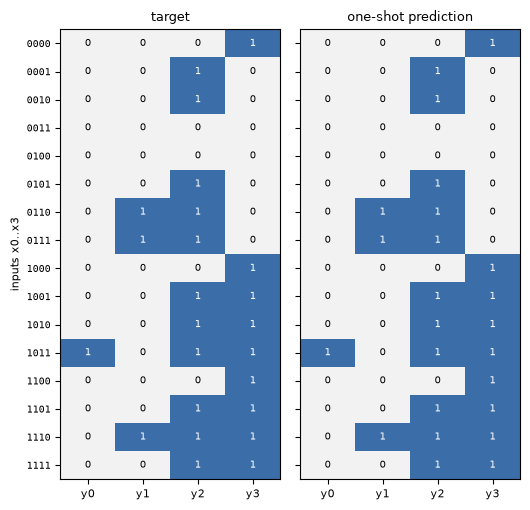

==== shallow_n4_m4_q2_2


generated: <start> ( x0 OR x1 OR x2 OR x3 ) XOR NOT x2 <next output> ( x0 XOR x1 ) AND NOT x2 <next output> x3 <next output> x0 OR x1 OR x2 OR x3 <end>
y0 = (x0 OR x1 OR x2 OR x3) XOR NOT x2
y1 = (x0 XOR x1) AND NOT x2
y2 = x3
y3 = x0 OR x1 OR x2 OR x3
wrong cells: 0 of 64  (0.0%)   model circuit: {'outputs': 4, 'gates': 11, 'depth': 2}   target circuit: {'outputs': 4, 'gates': 11, 'depth': 2}


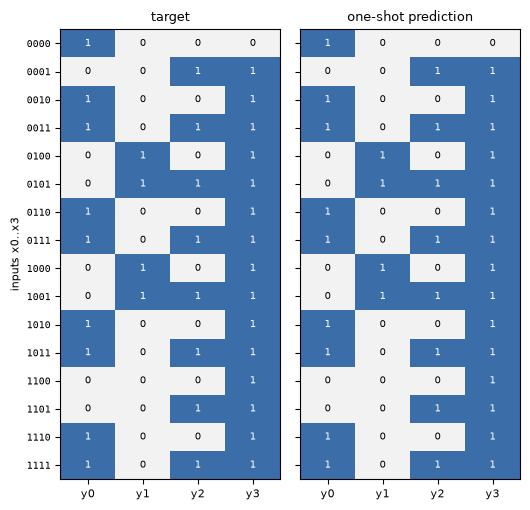

==== shallow_n3_m3_q2_0
generated: <start> x0 AND x1 AND NOT x2 <next output> ( x1 XOR x2 ) XOR NOT x1 <next output> NOT ( x1 OR x2 OR NOT x0 ) <end>
y0 = x0 AND x1 AND NOT x2
y1 = (x1 XOR x2) XOR NOT x1
y2 = NOT (x1 OR x2 OR NOT x0)
wrong cells: 0 of 24  (0.0%)   model circuit: {'outputs': 3, 'gates': 10, 'depth': 3}   target circuit: {'outputs': 3, 'gates': 10, 'depth': 3}


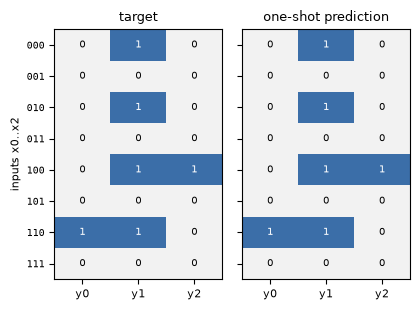

In [6]:
for s in [s for s in samples if s['kind'] == 'shallow'][1:]:
    print('====', s['id'])
    run_one_shot(s)

## 4. Deeper circuits: one-shot errors and XOR residual refinement

The next samples are generated at depth 6 to 10, beyond the training depth. One forward pass
gets most cells right but not all.

deep_n4_m4_q6_0 {'outputs': 4, 'gates': 21, 'depth': 5}


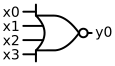

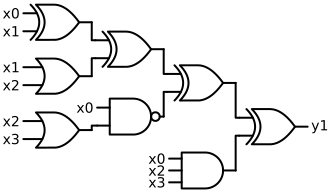

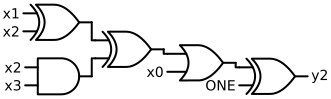

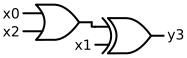

generated: <start> NOT ( x0 OR x1 OR x2 OR x3 ) <next output> ( x0 XOR x1 ) XOR NOT x3 <next output> NOT ( x0 OR x1 ) <next output> ( x0 OR x1 OR x2 ) XOR ( x1 AND x2 ) <end>
y0 = NOT (x0 OR x1 OR x2 OR x3)
y1 = (x0 XOR x1) XOR NOT x3
y2 = NOT (x0 OR x1)
y3 = (x0 OR x1 OR x2) XOR (x1 AND x2)
wrong cells: 10 of 64  (15.6%)   model circuit: {'outputs': 4, 'gates': 13, 'depth': 2}   target circuit: {'outputs': 4, 'gates': 21, 'depth': 5}


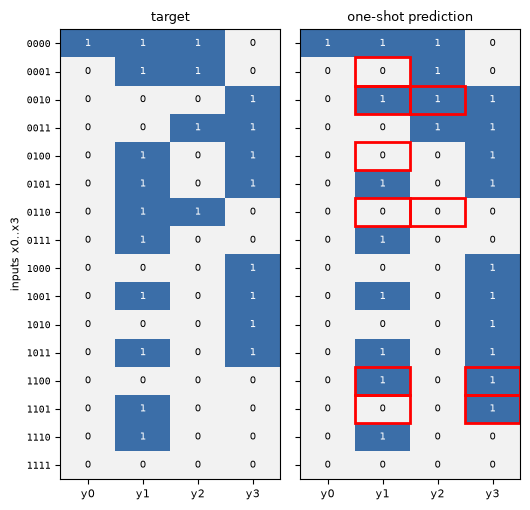

In [7]:
deep = [s for s in samples if s['kind'] == 'deep']
sample = deep[0]
target = C.parse(sample['circuit'])
print(sample['id'], C.stats(target))
for d in C.draw(target):
    display(d)
outs, pred = run_one_shot(sample)

**XOR residual refinement.** The residual `R` holds the cells that are still wrong (initially
`R = Y`). At each step the model synthesizes a circuit for `R`, which is accepted if it
reduces the number of wrong cells, and `R <- R xor C(X)`. Because XOR is its own inverse,
the XOR of all accepted circuits computes `Y` once `R = 0`. If a step does not help, the
residual is split by a random mask and both halves are synthesized; anything left at the end
would be written out exactly as a sum of products. The final circuit is always exact.

step 1 (direct): 10 wrong cells left
step 2 (direct): 4 wrong cells left
step 3 (direct): 0 wrong cells left


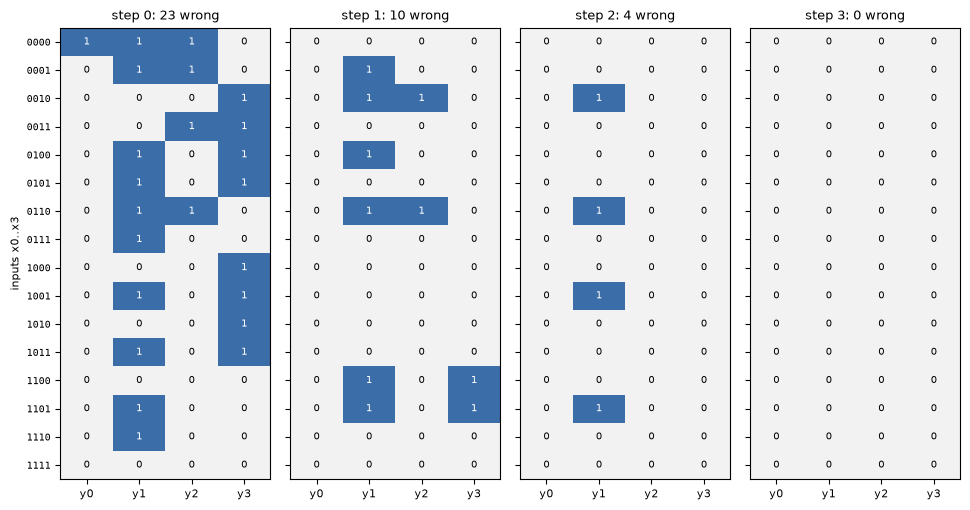

In [8]:
res = H.xor_refine(model, np.array(sample['truth_table'], dtype=np.uint8), verbose=True)
n = sample['n']
hist = res['history']
show_tables([h['residual'] for h in hist], [f"step {h['step']}: {h['wrong_cells']} wrong" for h in hist], n)

step 1 (direct) circuit for the residual:
   y0 : NOT (x0 OR x1 OR x2 OR x3)
   y1 : (x0 XOR x1) XOR NOT x3
   y2 : NOT (x0 OR x1)
   y3 : (x0 OR x1 OR x2) XOR (x1 AND x2)
step 2 (direct) circuit for the residual:
   y0 : 0
   y1 : (x1 OR x2) XOR (x2 OR x3)
   y2 : NOT (x0 OR x3 OR NOT x2)
   y3 : x0 AND x1 AND NOT x2
step 3 (direct) circuit for the residual:
   y0 : 0
   y1 : (x0 XOR x2) AND (x2 XOR x3)
   y2 : 0
   y3 : 0

final circuit exact: True | refinement steps: 3 | SOP completion used: False
final circuit: {'outputs': 4, 'gates': 30, 'depth': 4}    target circuit: {'outputs': 4, 'gates': 21, 'depth': 5}


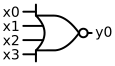

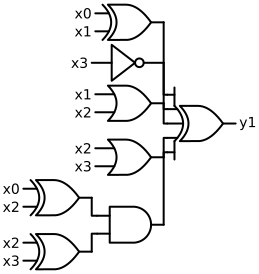

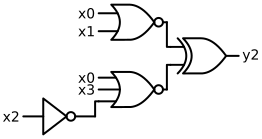

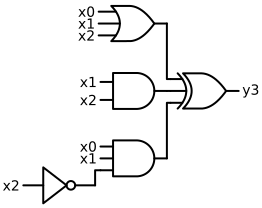

In [9]:
for h in hist[1:]:
    print(f"step {h['step']} ({h['how']}) circuit for the residual:")
    for j, o in enumerate(h['circuit']):
        print(f'   y{j} : {C.pretty(o)}')
final = res['outputs']
Y = np.array(sample['truth_table'], dtype=np.uint8)
print()
print('final circuit exact:', bool((C.evaluate(final, n) == Y).all()),
      '| refinement steps:', res['steps'], '| SOP completion used:', res['sop_completion'])
print('final circuit:', C.stats(final), '   target circuit:', sample['circuit_stats'])
for d in C.draw(final, max_gates=80):
    display(d)

## 5. All samples

In [10]:
print(f"{'sample':24s} {'one-shot wrong cells':>21s} {'refinement steps':>17s} {'exact':>6s}")
for s in samples:
    Y = np.array(s['truth_table'], dtype=np.uint8)
    _, pred, _ = H.one_shot(model, Y)
    wrong = Y.size if pred is None else int((pred != Y).sum())
    res = H.xor_refine(model, Y)
    exact = bool((C.evaluate(res['outputs'], s['n']) == Y).all())
    print(f"{s['id']:24s} {wrong:>21d} {res['steps']:>17d} {str(exact):>6s}")

sample                    one-shot wrong cells  refinement steps  exact
shallow_n4_m4_q2_0                           0                 1   True


shallow_n4_m4_q2_1                           0                 1   True
shallow_n4_m4_q2_2                           0                 1   True
shallow_n3_m3_q2_0                           0                 1   True


deep_n4_m4_q6_0                             10                 3   True
deep_n4_m4_q6_b0                             5                 2   True


deep_n4_m4_q6_b1                             7                 3   True


## 6. Try your own circuit

Write a circuit in the token language (one output per line, at most 5 inputs and 5 outputs),
compute its truth table, and run the model and the outer loop on it.

In [11]:
my_circuit = '''( 0 ⊻ 1 ) ∧ ( 2 ∨ ~ 3 )
( ( 0 ∧ 1 ) ∨ ( 2 ∧ 3 ) ) ⊻ ( 1 ∨ 2 )
~ ( 0 ∨ 3 )'''
n = 4
Y = C.evaluate(C.parse(my_circuit), n)
outs, pred, ids = H.one_shot(model, Y)
print('one-shot wrong cells:', Y.size if pred is None else int((pred != Y).sum()))
res = H.xor_refine(model, Y, verbose=True)
print('final:', C.stats(res['outputs']))
for j, o in enumerate(res['outputs']):
    print(f'y{j} = {C.pretty(o)}')

one-shot wrong cells: 5
step 1 (direct): 5 wrong cells left
step 2 (direct): 3 wrong cells left
step 3 (direct): 1 wrong cells left
step 4 (direct): 0 wrong cells left
final: {'outputs': 3, 'gates': 37, 'depth': 3}
y0 = (x0 XOR x2) XOR (x1 XOR x2) XOR ((x0 XOR x1) AND x3 AND NOT x2)
y1 = ((x0 OR x1 OR x2) AND (x1 OR x2) AND (x1 OR x2 OR x3) AND (x1 XOR x2) AND NOT x3) XOR ((x0 XOR x2) AND x1 AND NOT x2) XOR (x1 AND (x2 XOR x3) AND NOT x2) XOR (x1 AND x2 AND NOT x0 AND NOT x3)
y2 = NOT (x0 OR x3)
